# 07 — Part H final evaluation and recommendation


## 1. Freeze the candidates and the comparison



In [1]:
from pathlib import Path
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve

root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
cleaned = root / 'data' / 'processed' / 'loan_default_cleaned.csv'
if not cleaned.is_file():
    raise FileNotFoundError('Open Notebook 07 from the project root or the notebooks folder.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.data_preparation import BASELINE_EXCLUSIONS, split_loan_data
from src.model_ensemble import MEMBERS, make_ensemble
from src.model_evaluation import evaluate_holdout, paired_ap_interval
from src.model_tuning import MODEL_NAMES, make_pipeline

part_f = root / 'outputs' / 'tables' / 'part_f'
part_g = root / 'outputs' / 'tables' / 'part_g'
tables = root / 'outputs' / 'tables' / 'part_h'
figures = root / 'outputs' / 'figures' / 'part_h'
tables.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)

settings = json.loads((part_f / 'selected_parameters.json').read_text(encoding='utf-8'))
handoff = json.loads((part_g / 'selected_ensemble.json').read_text(encoding='utf-8'))
assert handoff['members'] == list(MEMBERS.values())
assert handoff['member_parameters'] == {name: settings[name] for name in MEMBERS.values()}
development = pd.read_csv(part_g / 'ensemble_comparison.csv').set_index('model')
reference = development.loc[list(MODEL_NAMES), 'ap_mean'].idxmax()
ensemble_name = handoff['method']
assert ensemble_name == development.loc[['Soft voting', 'Stacking'], 'ap_mean'].idxmax()

models = {name: make_pipeline(name, settings[name]) for name in MODEL_NAMES}
models[ensemble_name] = make_ensemble(ensemble_name, handoff['member_parameters'])
X_dev, X_holdout, y_dev, y_holdout = split_loan_data(pd.read_csv(cleaned))
assert len(X_dev) == 118936 and len(X_holdout) == 29734
assert X_dev.index.intersection(X_holdout.index).empty
print(f'Development: {len(X_dev):,} | Holdout: {len(X_holdout):,} | Holdout defaults: {y_holdout.sum():,} ({y_holdout.mean():.2%})')
print(f'{platform.system()} / {platform.machine()} | scikit-learn {sklearn.__version__} | XGBoost {xgboost.__version__}')

Matplotlib is building the font cache; this may take a moment.


Development: 118,936 | Holdout: 29,734 | Holdout defaults: 7,328 (24.65%)
Darwin / arm64 | scikit-learn 1.9.0 | XGBoost 3.4.1


## 2. Score all four models on the reserved rows


Logistic Regression: fitted and scored.


Random Forest: fitted and scored.


XGBoost: fitted and scored.


Stacking: fitted and scored.


Constant-score AP reference: 0.2465


,ap,roc_auc,brier,reviewed,defaults_caught,review_precision,review_recall
model,,,,,,,
Stacking,0.5897,0.7558,0.1470,2974,2196,0.7384,0.2997
XGBoost,0.5895,0.7555,0.1468,2974,2196,0.7384,0.2997
Random Forest,0.5761,0.7506,0.1498,2974,2151,0.7233,0.2935
Logistic Regression,0.5244,0.7136,0.1579,2974,1966,0.6611,0.2683


,accuracy_050,precision_050,recall_050,f1_050,tn_050,fp_050,fn_050,tp_050
model,,,,,,,,
Stacking,0.8012,0.7433,0.2956,0.4230,21658,748,5162,2166
XGBoost,0.8014,0.7844,0.2676,0.3991,21867,539,5367,1961
Random Forest,0.7964,0.8117,0.2265,0.3542,22021,385,5668,1660
Logistic Regression,0.7869,0.7242,0.2186,0.3358,21796,610,5726,1602


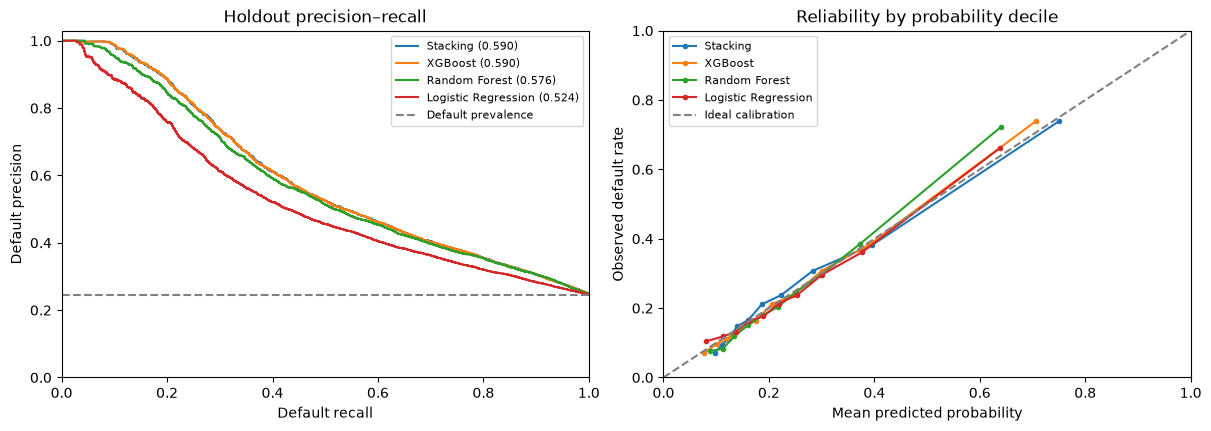

In [2]:
scores, stress, predictions = evaluate_holdout(models, X_dev, y_dev, X_holdout, y_holdout)
assert scores['reviewed'].eq(int(np.ceil(len(y_holdout) * 0.10))).all()
assert scores[['tn_050', 'fp_050', 'fn_050', 'tp_050']].sum(axis=1).eq(len(y_holdout)).all()
scores['development_cv_ap'] = development.loc[scores.index, 'ap_mean']
scores = scores.sort_values('ap', ascending=False)
scores.to_csv(tables / 'holdout_metrics.csv')
print(f'Constant-score AP reference: {y_holdout.mean():.4f}')
display(scores[['ap', 'roc_auc', 'brier', 'reviewed', 'defaults_caught',
                'review_precision', 'review_recall']].round(4))
display(scores[['accuracy_050', 'precision_050', 'recall_050', 'f1_050',
                'tn_050', 'fp_050', 'fn_050', 'tp_050']].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
for name in scores.index:
    p = predictions[name]
    precision, recall, _ = precision_recall_curve(y_holdout, p)
    axes[0].plot(recall, precision, label=f'{name} ({scores.loc[name, "ap"]:.3f})')
    observed, predicted = calibration_curve(y_holdout, p, n_bins=10, strategy='quantile')
    axes[1].plot(predicted, observed, marker='o', markersize=3, label=name)
axes[0].axhline(y_holdout.mean(), linestyle='--', color='grey', label='Default prevalence')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='grey', label='Ideal calibration')
axes[0].set(xlabel='Default recall', ylabel='Default precision', title='Holdout precision–recall',
            xlim=(0, 1), ylim=(0, 1.03))
axes[1].set(xlabel='Mean predicted probability', ylabel='Observed default rate',
            title='Reliability by probability decile', xlim=(0, 1), ylim=(0, 1))
for ax in axes:
    ax.legend(fontsize=8)
fig.savefig(figures / 'holdout_curves.png', dpi=160)
plt.show()

## 3. Check uncertainty, overfitting and robustness

In [3]:
interval = paired_ap_interval(y_holdout, predictions[ensemble_name], predictions[reference])
interval_table = pd.DataFrame([{'candidate': ensemble_name, 'reference': reference, **interval}])
interval_table.to_csv(tables / 'paired_ap_interval.csv', index=False)
stress.to_csv(tables / 'missing_income_stress.csv')
display(interval_table.round(4))
display(scores[['train_ap', 'development_cv_ap', 'ap', 'train_holdout_ap_gap']].round(4))
display(stress.round(4))

,candidate,reference,ap_difference_pp,ci_low_pp,ci_high_pp,resamples
0,Stacking,XGBoost,0.0196,-0.0089,0.0476,1000


,train_ap,development_cv_ap,ap,train_holdout_ap_gap
model,,,,
Stacking,0.6144,0.5798,0.5897,0.0247
XGBoost,0.6115,0.5794,0.5895,0.0220
Random Forest,0.6285,0.5665,0.5761,0.0524
Logistic Regression,0.5199,0.5192,0.5244,-0.0045


,original_ap,income_missing_ap,ap_change_pp,original_defaults_caught,income_missing_defaults_caught
model,,,,,
Logistic Regression,0.5244,0.4503,-7.4124,1966,1707
Random Forest,0.5761,0.5150,-6.1120,2151,1858
XGBoost,0.5895,0.4960,-9.3469,2196,1845
Stacking,0.5897,0.4995,-9.0208,2196,1854


## 4. Compare computational cost and explainability

In [4]:
display(scores[['fit_seconds', 'batch_predict_ms_per_1000']].round(3))
feature_rows = []
for name, model in models.items():
    pipelines = {name: model} if name in MODEL_NAMES else dict(model.named_estimators_)
    for component, pipeline in pipelines.items():
        prepared = pipeline.named_steps['prepare']
        assert set(prepared.selected_features_).isdisjoint(['status', *BASELINE_EXCLUSIONS])
        feature_rows.append({
            'model': name, 'component': component,
            'selected_input_count': len(prepared.selected_features_),
            'encoded_feature_count': len(prepared.get_feature_names_out()),
            'inputs': ', '.join(prepared.selected_features_),
        })
features = pd.DataFrame(feature_rows)
features.to_csv(tables / 'final_feature_usage.csv', index=False)
display(features.drop(columns='inputs'))

,fit_seconds,batch_predict_ms_per_1000
model,,
Stacking,13.543,5.620
XGBoost,1.546,2.083
Random Forest,2.683,3.686
Logistic Regression,1.489,1.590


,model,component,selected_input_count,encoded_feature_count
0,Logistic Regression,Logistic Regression,20,47
1,Random Forest,Random Forest,20,47
2,XGBoost,XGBoost,20,47
3,Stacking,xgb,20,47
4,Stacking,rf,20,47


## 5. Recommend a model for this project



In [5]:
use_ensemble = (
    interval['ci_low_pp'] > 0
    and scores.loc[ensemble_name, 'defaults_caught'] >= scores.loc[reference, 'defaults_caught']
)
recommendation = ensemble_name if use_ensemble else reference
print(f'Recommended project model: {recommendation}')
print(f'Highest observed holdout AP: {scores.index[0]} ({scores.iloc[0].ap:.5f})')
print(f'{ensemble_name} minus {reference}: {interval["ap_difference_pp"]:+.3f} AP pp '
      f'(95% interval {interval["ci_low_pp"]:+.3f} to {interval["ci_high_pp"]:+.3f}).')
for name in (ensemble_name, reference):
    row = scores.loc[name]
    print(f'{name}: caught {int(row.defaults_caught):,}/{int(y_holdout.sum()):,} defaults '
          f'with {int(row.reviewed):,} reviews; {row.batch_predict_ms_per_1000:.2f} ms per 1,000 rows.')

Recommended project model: XGBoost
Highest observed holdout AP: Stacking (0.58970)
Stacking minus XGBoost: +0.020 AP pp (95% interval -0.009 to +0.048).
Stacking: caught 2,196/7,328 defaults with 2,974 reviews; 5.62 ms per 1,000 rows.
XGBoost: caught 2,196/7,328 defaults with 2,974 reviews; 2.08 ms per 1,000 rows.
